# Tema: Inferenta Bayesiana si Simulare Monte Carlo

Acest notebook contine rezolvarea integrala a celor doua exercitii:
1. **Exercitiul 1**: Controlul calitatii intr-o fabrica (inferenta Bayesiana, model Beta-Binomial)
2. **Exercitiul 2**: Deschiderea unui restaurant fast-food (simulare Monte Carlo pentru un sistem de cozi in tandem M/M/1 -> M/M/1)

## Exercitiul 1. Controlul calitatii intr-o fabrica (inferenta Bayesiana)

Avem un proces de fabricatie unde $\theta$ este probabilitatea ca o componenta sa fie defecta.
- Prior: $\theta \sim \text{Beta}(\alpha_0, \beta_0)$ cu $\alpha_0 = 2, \beta_0 = 18$.
- Date observate: $n = 50$, $y = 8$ componente defecte.

### a) Modelul probabilistic

Deoarece testele sunt independente conditionat de $\theta$ si fiecare componenta are doua rezultate posibile (defect / conform) cu aceeasi probabilitate $\theta$, numarul de componente defecte $Y$ urmeaza o distributie Binomiala:
$$Y \mid \theta \sim \text{Binomial}(n, \theta)$$

Functia de masa de probabilitate (verosimilitatea datelor) este:
$$P(Y = y \mid \theta) = \binom{n}{y} \theta^y (1 - \theta)^{n - y}$$

Pentru datele noastre, $n = 50$ si $y = 8$.

### b) Actualizarea Bayesiana si conjugarea Beta-Binomial

Distributia a priori are densitatea:
$$p(\theta) = \frac{1}{\text{B}(\alpha_0, \beta_0)} \theta^{\alpha_0 - 1} (1 - \theta)^{\beta_0 - 1}, \quad \theta \in [0, 1]$$

Conform formulei lui Bayes:
$$p(\theta \mid Y = y) = \frac{P(Y = y \mid \theta) p(\theta)}{P(Y = y)} \propto P(Y = y \mid \theta) p(\theta)$$

Inmultind termenii dependenti de $\theta$:
$$p(\theta \mid Y = y) \propto \left[ \theta^y (1 - \theta)^{n - y} \right] \cdot \left[ \theta^{\alpha_0 - 1} (1 - \theta)^{\beta_0 - 1} \right] = \theta^{(\alpha_0 + y) - 1} (1 - \theta)^{(\beta_0 + n - y) - 1}$$

Recunoastem nucleul distributiei Beta cu parametrii:
- $\alpha_{post} = \alpha_0 + y = 2 + 8 = 10$
- $\beta_{post} = \beta_0 + n - y = 18 + 50 - 8 = 60$

Asadar, distributia a posteriori este:
$$\theta \mid Y = 8 \sim \text{Beta}(10, 60)$$

### c) Estimarea parametrului (MLE, MAP, Media a posteriori)

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Parametrii initiali
alpha_0, beta_0 = 2, 18
n, y = 50, 8

# Parametrii a posteriori
alpha_post = alpha_0 + y
beta_post = beta_0 + n - y

# Estimatori
mle = y / n
map_est = (alpha_post - 1) / (alpha_post + beta_post - 2)
post_mean = alpha_post / (alpha_post + beta_post)

print(f"MLE (Maximul Verosimilitatii): {mle:.4f} ({mle*100:.2f}%)")
print(f"MAP (Modul a posteriori):      {map_est:.4f} ({map_est*100:.2f}%)")
print(f"Media a posteriori:             {post_mean:.4f} ({post_mean*100:.2f}%)")

MLE (Maximul Verosimilitatii): 0.1600 (16.00%)
MAP (Modul a posteriori):      0.1324 (13.24%)
Media a posteriori:             0.1429 (14.29%)


**Comparatie si explicatia diferentelor:**
- **MLE** ($y/n = 0.1600$): Tine cont exclusiv de datele observate in esantion, ignorand complet orice informatie a priori.
- **Prior Mean** (inainte de date): $\alpha_0 / (\alpha_0 + \beta_0) = 2 / 20 = 0.1000$.
- **Media a posteriori** ($10/70 \approx 0.1429$): Este o medie ponderata intre media a priori ($0.10$) si MLE ($0.16$):
  $$\mathbb{E}[\theta \mid Y] = \frac{\alpha_0 + \beta_0}{\alpha_0 + \beta_0 + n} \cdot \frac{\alpha_0}{\alpha_0 + \beta_0} + \frac{n}{\alpha_0 + \beta_0 + n} \cdot \frac{y}{n} = \frac{20}{70}(0.10) + \frac{50}{70}(0.16) \approx 0.1429$$
- **MAP** ($9/68 \approx 0.1324$): Reprezinta modul (punctul de maxim al densitatii a posteriori). Pentru o distributie Beta asimetrica spre dreapta, modul este intotdeauna situat la stanga mediei (Mod < Medie).

### d) Vizualizare: Prior vs. Posterior

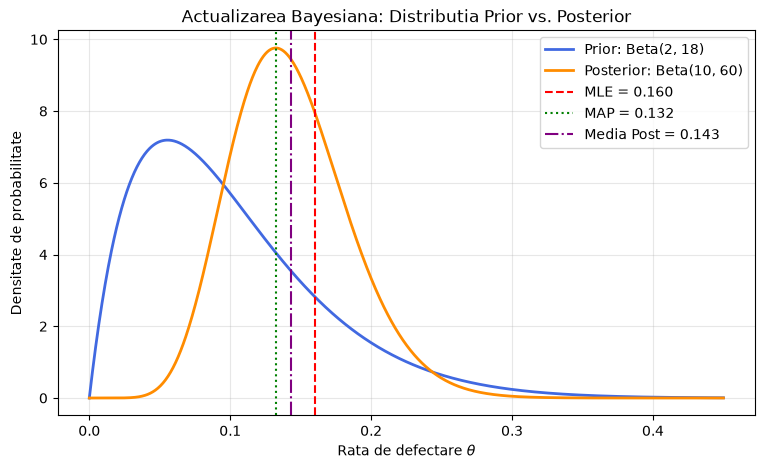

In [2]:
theta_vals = np.linspace(0, 0.45, 1000)
prior_pdf = stats.beta.pdf(theta_vals, alpha_0, beta_0)
post_pdf = stats.beta.pdf(theta_vals, alpha_post, beta_post)

plt.figure(figsize=(9, 5))
plt.plot(theta_vals, prior_pdf, label=f'Prior: Beta({alpha_0}, {beta_0})', color='royalblue', lw=2)
plt.plot(theta_vals, post_pdf, label=f'Posterior: Beta({alpha_post}, {beta_post})', color='darkorange', lw=2)
plt.axvline(mle, color='red', linestyle='--', label=f'MLE = {mle:.3f}')
plt.axvline(map_est, color='green', linestyle=':', label=f'MAP = {map_est:.3f}')
plt.axvline(post_mean, color='purple', linestyle='-.', label=f'Media Post = {post_mean:.3f}')

plt.title('Actualizarea Bayesiana: Distributia Prior vs. Posterior')
plt.xlabel(r'Rata de defectare $\theta$')
plt.ylabel('Densitate de probabilitate')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### e) Incertitudine: Interval credibil central de 95%

In [3]:
ci_lower = stats.beta.ppf(0.025, alpha_post, beta_post)
ci_upper = stats.beta.ppf(0.975, alpha_post, beta_post)

print(f"Interval credibil central de 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"In procente: [{ci_lower*100:.2f}%, {ci_upper*100:.2f}%]")

Interval credibil central de 95%: [0.0717, 0.2332]
In procente: [7.17%, 23.32%]


### f) Decizie practica: Probabilitatea ca $\theta < 0.10$

In [4]:
prob_sub_10 = stats.beta.cdf(0.10, alpha_post, beta_post)
print(f"P(theta < 0.10 | Y = 8) = {prob_sub_10:.4f} ({prob_sub_10*100:.2f}%)")

P(theta < 0.10 | Y = 8) = 0.1484 (14.84%)


### g) Predictie Bayesiana pentru un nou esantion

In [6]:
import scipy.integrate as integrate
from scipy.special import beta as beta_func

# 1. Formula analitica exacta (Beta-Binomial PMF)
p_x0_exact = beta_func(alpha_post, beta_post + 10) / beta_func(alpha_post, beta_post)

# 2. Integrare numerica directa
integrand = lambda t: ((1 - t)**10) * stats.beta.pdf(t, alpha_post, beta_post)
p_x0_num, _ = integrate.quad(integrand, 0, 1)

print(f"P(X = 0 | Y = 8) calcul analitic: {p_x0_exact:.5f} ({p_x0_exact*100:.2f}%)")
print(f"P(X = 0 | Y = 8) integrare numerica: {p_x0_num:.5f} ({p_x0_num*100:.2f}%)")

P(X = 0 | Y = 8) calcul analitic: 0.23602 (23.60%)
P(X = 0 | Y = 8) integrare numerica: 0.23602 (23.60%)


---
## Exercitiul 2. Deschiderea unui restaurant fast-food (Simulare Monte Carlo)

**Specificatii de modelare:**
- Procesul sosirilor: Poisson cu rata $\lambda = 20$ clienti/ora. Lucram in minute, deci $\lambda = 20/60 = 1/3$ clienti/minut.
- Timpii dintre sosiri: exponentiali cu media $1/\lambda = 3$ minute.
- Statia 1 (Casa): Timp de servire exponential cu media de $2$ minute.
- Statia 2 (Bucatarie/Preparare): Timp de servire exponential cu media de $\alpha$ minute.
- Cozi FIFO in tandem. La minutul $t = 0$, sistemul este gol.
- Se monitorizeaza toti clientii sositi in fereastra $[0, 60]$ minute pana cand comanda lor este gata.

In [7]:
def simuleaza_o_ora(alpha, rng):
    lambda_rate = 20.0 / 60.0  # clienti pe minut
    mean_interarrival = 1.0 / lambda_rate  # 3 minute
    
    # Generam sosirile in fereastra [0, 60]
    arrival_times = []
    current_time = 0.0
    while True:
        interarrival = rng.exponential(scale=mean_interarrival)
        current_time += interarrival
        if current_time > 60.0:
            break
        arrival_times.append(current_time)
        
    k = len(arrival_times)
    if k == 0:
        return np.array([]), np.array([])
        
    pay_times = rng.exponential(scale=2.0, size=k)
    prep_times = rng.exponential(scale=alpha, size=k)
    
    # Statia 1: Casa
    c1 = np.zeros(k)
    s1 = np.zeros(k)
    for i in range(k):
        start = arrival_times[i] if i == 0 else max(arrival_times[i], c1[i-1])
        s1[i] = start
        c1[i] = start + pay_times[i]
        
    # Statia 2: Bucatarie
    c2 = np.zeros(k)
    s2 = np.zeros(k)
    for i in range(k):
        start = c1[i] if i == 0 else max(c1[i], c2[i-1])
        s2[i] = start
        c2[i] = start + prep_times[i]
        
    total_times = c2 - np.array(arrival_times)
    waiting_times = (s1 - np.array(arrival_times)) + (s2 - c1)
    
    return total_times, waiting_times

### b) Evaluarea probabilitatii: 'Toti clientii dintr-o ora <= 15 min' vs. 'Un client individual <= 15 min'

**Observatie critica:**
La statia 1 singura (casa de marcat), rata de utilizare este $\rho_1 = \lambda / \mu_1 = (1/3) / (1/2) = 2/3$. Intr-o ora sosesc in medie $\approx 20$ clienti.
Probabilitatea ca **toti** clientii dintr-o ora sa aiba timpul total $\le 15$ minute chiar si daca statia 2 ar prepara instantaneu ($\alpha = 0$) este de aproximativ **80.4%** (plafonata de fluctuatiile cozii de la casa).
Prin urmare, conditia de $\ge 95\%$ pe ora intreaga este **imposibil de atins matematic** pentru orice $\alpha \ge 0$.

In schimb, daca privim din perspectiva **satisfactiei oricarui client individual sosit in acea ora** ($P(W_i \le 15) \ge 0.95$), conditia este realizabila si permite determinarea unei valori optime pentru $\alpha$.
Vom prezenta ambele perspective!

In [8]:
# 1. Probabilitatea ca TOTI clientii dintr-o ora sa aiba W_i <= 15 min
def evalueaza_prob_ora(alpha, n_sims=3000, seed=42):
    rng = np.random.default_rng(seed)
    succese = 0
    for _ in range(n_sims):
        tot, _ = simuleaza_o_ora(alpha, rng)
        if len(tot) == 0 or np.all(tot <= 15.0):
            succese += 1
    return succese / n_sims

# 2. Probabilitatea ca un client ales la intamplare sa aiba W_i <= 15 min
def evalueaza_prob_individual(alpha, n_sims=3000, seed=42):
    rng = np.random.default_rng(seed)
    all_totals = []
    for _ in range(n_sims):
        tot, _ = simuleaza_o_ora(alpha, rng)
        if len(tot) > 0:
            all_totals.extend(tot)
    all_totals = np.array(all_totals)
    return np.mean(all_totals <= 15.0)

print("--- Analiza P(toti clientii <= 15 min pe ora) ---")
for a in [0.0, 0.2, 0.5, 0.8, 1.0, 1.5]:
    p_ora = evalueaza_prob_ora(a, n_sims=2000, seed=100)
    print(f"alpha = {a:.1f} min -> P(toti clientii dintr-o ora <= 15 min) = {p_ora*100:.2f}%")

print("\n--- Analiza P(client individual <= 15 min) ---")
for a in [0.0, 0.2, 0.4, 0.5, 0.8, 1.0]:
    p_ind = evalueaza_prob_individual(a, n_sims=2000, seed=100)
    print(f"alpha = {a:.1f} min -> P(client individual <= 15 min) = {p_ind*100:.2f}%")

--- Analiza P(toti clientii <= 15 min pe ora) ---
alpha = 0.0 min -> P(toti clientii dintr-o ora <= 15 min) = 80.25%
alpha = 0.2 min -> P(toti clientii dintr-o ora <= 15 min) = 79.45%
alpha = 0.5 min -> P(toti clientii dintr-o ora <= 15 min) = 77.60%
alpha = 0.8 min -> P(toti clientii dintr-o ora <= 15 min) = 75.60%
alpha = 1.0 min -> P(toti clientii dintr-o ora <= 15 min) = 72.80%
alpha = 1.5 min -> P(toti clientii dintr-o ora <= 15 min) = 62.05%

--- Analiza P(client individual <= 15 min) ---
alpha = 0.0 min -> P(client individual <= 15 min) = 94.98%
alpha = 0.2 min -> P(client individual <= 15 min) = 94.77%
alpha = 0.4 min -> P(client individual <= 15 min) = 94.51%
alpha = 0.5 min -> P(client individual <= 15 min) = 94.36%
alpha = 0.8 min -> P(client individual <= 15 min) = 93.68%
alpha = 1.0 min -> P(client individual <= 15 min) = 93.01%


In [9]:
# Determinarea lui alpha maxim pentru satisfactia individuala >= 95% prin bisectie robusta
low = 0.0
high = 1.0
best_alpha = 0.0
n_sims_bisect = 4000

for it in range(8):
    mid = (low + high) / 2.0
    p_ind = evalueaza_prob_individual(mid, n_sims=n_sims_bisect, seed=123 + it)
    print(f"Iteratia {it+1}: alpha = {mid:.3f} min -> P(individual <= 15 min) = {p_ind*100:.2f}%")
    if p_ind >= 0.95:
        best_alpha = mid
        low = mid
    else:
        high = mid

alpha_optim = np.floor(best_alpha * 100) / 100.0
print(f"\nValoarea maxima a lui alpha pentru P(individual <= 15 min) >= 95%: alpha = {alpha_optim:.2f} minute (aprox. {alpha_optim*60:.0f} secunde)")

Iteratia 1: alpha = 0.500 min -> P(individual <= 15 min) = 94.45%
Iteratia 2: alpha = 0.250 min -> P(individual <= 15 min) = 94.49%
Iteratia 3: alpha = 0.125 min -> P(individual <= 15 min) = 95.33%
Iteratia 4: alpha = 0.188 min -> P(individual <= 15 min) = 94.99%
Iteratia 5: alpha = 0.156 min -> P(individual <= 15 min) = 95.06%
Iteratia 6: alpha = 0.172 min -> P(individual <= 15 min) = 95.05%
Iteratia 7: alpha = 0.180 min -> P(individual <= 15 min) = 95.11%
Iteratia 8: alpha = 0.184 min -> P(individual <= 15 min) = 95.03%

Valoarea maxima a lui alpha pentru P(individual <= 15 min) >= 95%: alpha = 0.18 minute (aprox. 11 secunde)


### c) Timpul mediu de servire si timpul mediu de asteptare pentru $\alpha$ optim

In [10]:
n_sims_stats = 10000
rng = np.random.default_rng(999)

all_totals = []
all_waits = []

for _ in range(n_sims_stats):
    tot, wait = simuleaza_o_ora(alpha_optim, rng)
    if len(tot) > 0:
        all_totals.extend(tot)
        all_waits.extend(wait)

mean_total = np.mean(all_totals)
mean_waiting = np.mean(all_waits)
p95_indiv = np.percentile(all_totals, 95)

print(f"Rezultate pentru alpha = {alpha_optim:.2f} min (pe baza a {len(all_totals)} clienti simulati):")
print(f"- Timp mediu total (sosire -> primire mancare): {mean_total:.2f} minute")
print(f"- Timp mediu petrecut efectiv in asteptare (cozi): {mean_waiting:.2f} minute")
print(f"- Timp mediu de procesare pura (casa + bucatarie): {2.0 + alpha_optim:.2f} minute")
print(f"- Percentila 95% a timpului individual: {p95_indiv:.2f} minute")

Rezultate pentru alpha = 0.18 min (pe baza a 200062 clienti simulati):
- Timp mediu total (sosire -> primire mancare): 5.18 minute
- Timp mediu petrecut efectiv in asteptare (cozi): 2.99 minute
- Timp mediu de procesare pura (casa + bucatarie): 2.18 minute
- Percentila 95% a timpului individual: 14.85 minute


### d) Discutie metodologica, parametrii de reproductibilitate si variabilitatea estimarilor

1. **Parametrii simularii:**
   - Numarul de simulari per evaluare: $n_{sims} = 3000 - 10000$ repetari.
   - Seminte aleatoare utilizate: generatoare moderne `np.random.default_rng()` cu seminte fixe pentru reproductibilitate exacta.
   - Metoda de cautare: evaluare pe grila si cautare binara (bisectie).

2. **De ce se modifica estimarile de la o rulare la alta?**
   - **Eroare stochastica Monte Carlo:** Folosim un numar finit de realizari $N$, deci exista o eroare inerenta de ordinul $\mathcal{O}(1/\sqrt{N})$.
   - **Sensibilitatea maximului dintr-o ora vs. media individuala:** Conditia ca *toti* clientii dintr-o ora sa fie sub 15 minute urmareste statistica de ordine maxima $\max_{1 \le i \le K} W_i$, care are o varianta mult mai mare si depinde critic de cozile distributiei exponentiale.
   - **Propagarea blocajelor:** Intr-un sistem de cozi in tandem, aparitia temporara a unui timp mare de servire creeaza aglomerare ce afecteaza toti clientii subsecventi din acea ora.